## anomaly detection using DBSCAN

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

creating sample non linear data

In [3]:
np.random.seed(42)

# Normal Cluster 1: Average Health
cluster_1 = pd.DataFrame({
    'Glucose': np.random.normal(100, 10, 150),
    'BloodPressure': np.random.normal(80, 5, 150)
})

# Normal Cluster 2: Pre-diabetic but stable (DBSCAN handles multi-modal data well)
cluster_2 = pd.DataFrame({
    'Glucose': np.random.normal(140, 10, 100),
    'BloodPressure': np.random.normal(90, 5, 100)
})

# Anomalies: Random scattered points (The "Noise")
anomalies = pd.DataFrame({
    'Glucose': np.random.uniform(50, 250, 20),
    'BloodPressure': np.random.uniform(50, 150, 20)
})

# Combine and Shuffle
df = pd.concat([cluster_1, cluster_2, anomalies], ignore_index=True)
df

,Glucose,BloodPressure
0,104.967142,81.252464
1,98.617357,81.732241
2,106.476885,76.599876
3,115.230299,81.161268
4,97.658466,81.465362
...,...,...
265,154.902278,74.240973
266,132.079365,61.483682
267,246.475723,111.062004
268,72.407780,78.863055


preprocessing for the distance range

In [4]:
# DBSCAN calculates distance. If one feature is 0-1 and another is 0-1000, 
# the distance will be distorted. Scaling is mandatory.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['Glucose', 'BloodPressure']])

In [5]:
# eps=0.5: In standard deviation units (since we scaled).
# min_samples=5: A cluster needs at least 5 points.
dbscan = DBSCAN(eps=0.5, min_samples=5)

In [6]:
# Fit and predict (DBSCAN returns cluster labels directly)
# Labels: 0, 1, 2... are clusters. -1 is NOISE (Anomaly).
clusters = dbscan.fit_predict(X_scaled)
df['cluster'] = clusters

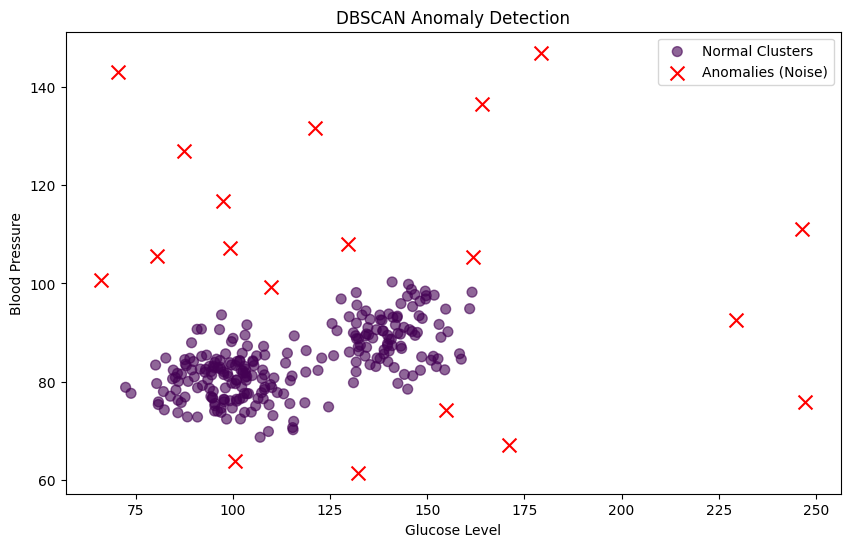

Number of anomalies detected: 19


In [7]:
plt.figure(figsize=(10, 6))

# Plot the "Normal" Clusters (Points where cluster != -1)
# We color them by their cluster ID to show DBSCAN found the two groups
plt.scatter(df[df['cluster'] != -1]['Glucose'], 
            df[df['cluster'] != -1]['BloodPressure'], 
            c=df[df['cluster'] != -1]['cluster'], 
            cmap='viridis', s=50, alpha=0.6, label='Normal Clusters')

# Plot the Anomalies (Points where cluster == -1)
anomalies_detected = df[df['cluster'] == -1]
plt.scatter(anomalies_detected['Glucose'], 
            anomalies_detected['BloodPressure'], 
            color='red', s=100, marker='x', label='Anomalies (Noise)')

plt.title('DBSCAN Anomaly Detection')
plt.xlabel('Glucose Level')
plt.ylabel('Blood Pressure')
plt.legend()
plt.show()

print(f"Number of anomalies detected: {len(anomalies_detected)}")